# 🖐️ Tongji Contactless Palmprint — Phân tích Khám phá Dữ liệu (EDA)

> **Môn học**: Nhận dạng mẫu (*Pattern Recognition*) — Đề tài 09 (Nhóm 01)  
> **Bộ dữ liệu**: Tongji Contactless Palmprint Dataset (600 Palm ID, 12.000 ảnh ROI mức xám $128 \times 128$)  
> **Mục tiêu Notebook**:
> 1. Khám phá cấu trúc, quy mô và tính cân bằng của tập dữ liệu giữa 2 phiên (Session 1 và Session 2).
> 2. Phân tích thống kê định lượng các thuộc tính chất lượng ảnh (Cường độ sáng, Độ tương phản, Độ sắc nét Laplacian).
> 3. Trực quan hóa mẫu ảnh thực tế và các dạng biến thiên nội lớp (Intra-class variations: ánh sáng, góc xoay, co giãn da).
> 4. Khám phá không gian đặc trưng và giảm chiều PCA (Eigenpalms, Scree plot và Session Shift 2D).

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Cấu hình đường dẫn và font hiển thị học thuật
WS = Path("..").resolve()
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False

manifest_path = WS / "data/metadata/manifest.csv"
df = pd.read_csv(manifest_path)
print(f"✅ Đã nạp manifest thành công: {len(df):,} mẫu ảnh ROI từ {df.palm_id.nunique()} Palm ID.")

✅ Đã nạp manifest thành công: 12,000 mẫu ảnh ROI từ 600 Palm ID.


## 1. Cấu trúc & Phân bố số lượng mẫu (Class & Session Balance)
Kiểm tra số lượng mẫu ảnh trên từng phiên và tính cân bằng lớp giữa 600 bàn tay độc lập.

,session,So_Palm_ID,Tong_so_anh,Anh_moi_Palm_min,Anh_moi_Palm_max
0,session1,600,6000,10,10
1,session2,600,6000,10,10


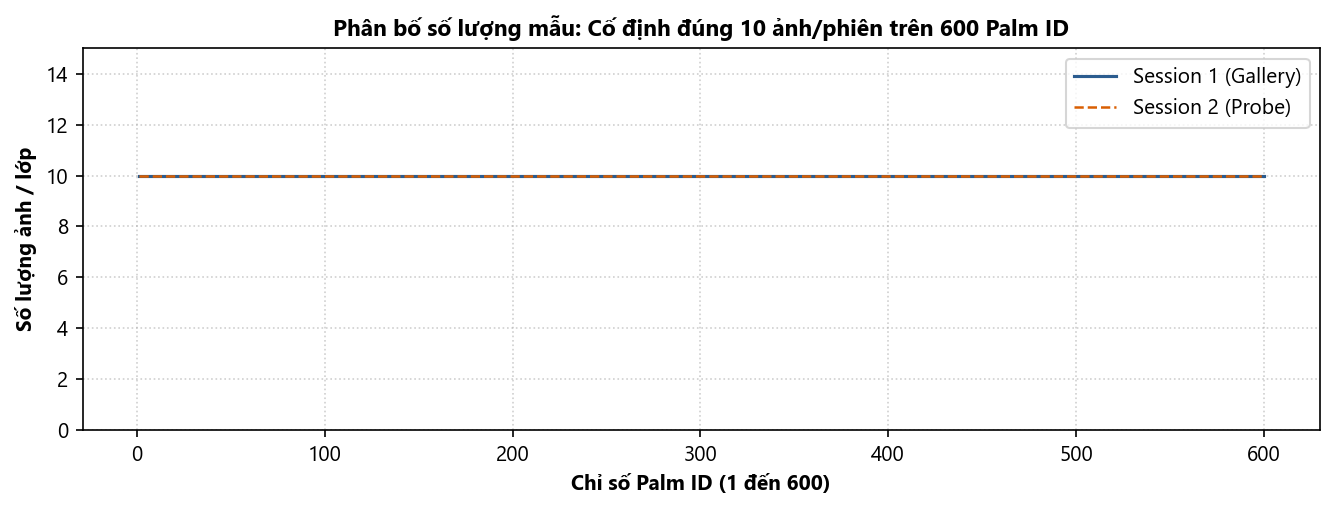

In [2]:
# Thống kê tổng hợp số lượng mẫu theo phiên
summary_df = (
    df.groupby("session")
    .agg(
        So_Palm_ID=("palm_id", "nunique"),
        Tong_so_anh=("sample_uid", "count"),
        Anh_moi_Palm_min=("palm_id", lambda x: x.value_counts().min()),
        Anh_moi_Palm_max=("palm_id", lambda x: x.value_counts().max()),
    )
    .reset_index()
)
display(summary_df)

# Biểu đồ kiểm chứng tính cân bằng lớp (10 ảnh/phiên trên toàn bộ 600 Palm ID)
pivot = df.groupby(["session", "palm_id"]).size().unstack(0, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.5), dpi=150)
ax.plot(pivot.index, pivot["session1"], label="Session 1 (Gallery)", color="#2b5c8f", lw=1.5)
ax.plot(pivot.index, pivot["session2"], label="Session 2 (Probe)", color="#d95f02", lw=1.2, ls="--")
ax.set_xlabel("Chỉ số Palm ID (1 đến 600)", fontsize=10, fontweight="bold")
ax.set_ylabel("Số lượng ảnh / lớp", fontsize=10, fontweight="bold")
ax.set_title("Phân bố số lượng mẫu: Cố định đúng 10 ảnh/phiên trên 600 Palm ID", fontsize=11, fontweight="bold")
ax.set_ylim(0, 15)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 2. Phân tích Thuộc tính Chất lượng Ảnh (Image Quality Analysis)
Đo lường 3 chỉ số cấp độ pixel trên 12.000 ảnh:
- **Brightness**: Cường độ sáng trung bình pixel.
- **Contrast**: Độ lệch chuẩn mức xám (độ tương phản).
- **Blur Proxy**: Biến sai toán tử Laplace $\text{Var}(\nabla^2 I)$ đo độ sắc nét nếp vân.

brightness                       contrast                     \
               mean    std    min     max     mean   std   min    max   
session                                                                 
session1     131.50  26.35  67.72  222.47    17.65  5.08  6.20  39.26   
session2     132.59  22.40  64.70  208.32    17.80  4.41  7.82  35.08   

         blur_proxy                       
               mean    std   min     max  
session                                   
session1      27.58  14.05  4.22  101.64  
session2      27.79  12.94  4.97  116.03

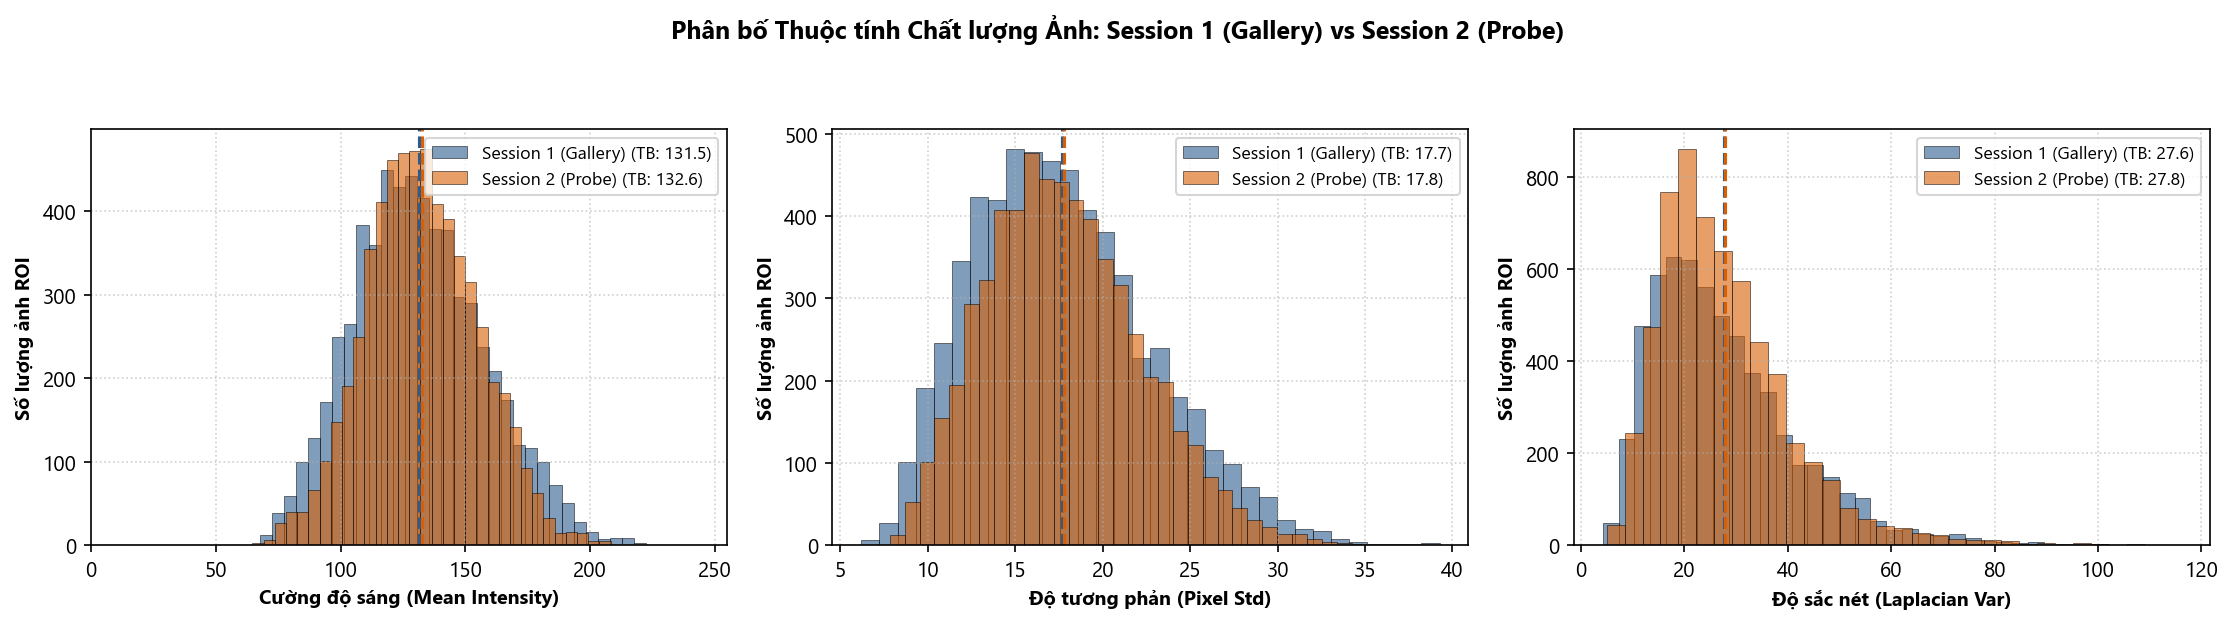

In [3]:
# Bảng thống kê định lượng chất lượng ảnh Session 1 vs Session 2
quality_stats = (
    df.groupby("session")[["brightness", "contrast", "blur_proxy"]]
    .agg(["mean", "std", "min", "max"])
    .round(2)
)
display(quality_stats)

# Trực quan hóa phân bố 3 chỉ số chất lượng ảnh (1x3 panel)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=150)
metrics = [
    ("brightness", "Cường độ sáng (Mean Intensity)", [0, 255]),
    ("contrast", "Độ tương phản (Pixel Std)", None),
    ("blur_proxy", "Độ sắc nét (Laplacian Var)", None),
]
colors = {"session1": "#2b5c8f", "session2": "#d95f02"}
labels = {"session1": "Session 1 (Gallery)", "session2": "Session 2 (Probe)"}

for idx, (col, title, xlim) in enumerate(metrics):
    ax = axes[idx]
    for s_name in ["session1", "session2"]:
        data = df[df.session == s_name][col]
        m = data.mean()
        ax.hist(data, bins=32, alpha=0.6, color=colors[s_name], edgecolor="black", lw=0.4, label=f"{labels[s_name]} (TB: {m:.1f})")
        ax.axvline(m, color=colors[s_name], linestyle="--", lw=1.5)
    ax.set_xlabel(title, fontsize=9.5, fontweight="bold")
    ax.set_ylabel("Số lượng ảnh ROI", fontsize=9.5, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8.5)
    if xlim:
        ax.set_xlim(xlim)

fig.suptitle("Phân bố Thuộc tính Chất lượng Ảnh: Session 1 (Gallery) vs Session 2 (Probe)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 3. Trực quan hóa Biến thiên Nội lớp (Visual Intra-Class Variations)
Minh họa sự khác biệt trực quan giữa ảnh chụp Session 1 (Gallery) và Session 2 (Probe) của cùng một người sau khoảng thời gian vài tuần đến một tháng.

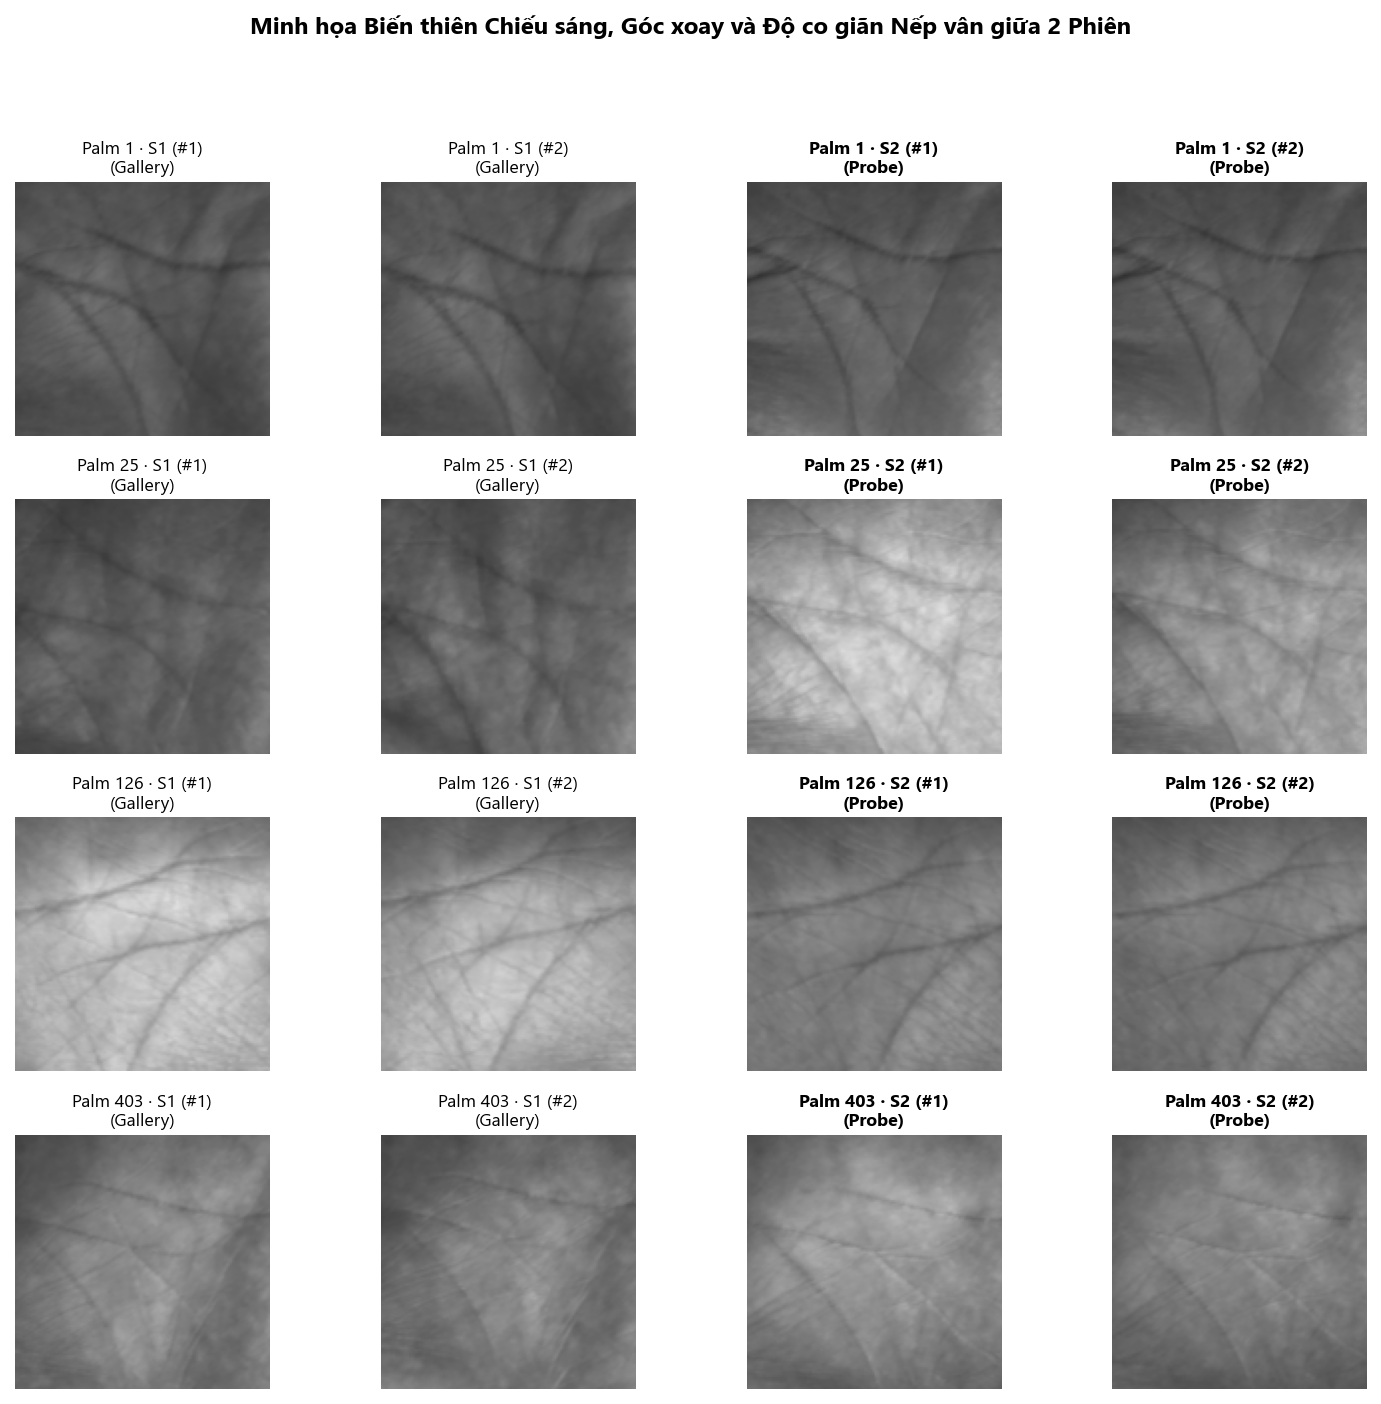

In [4]:
# Trực quan hóa mẫu ảnh thực tế của 4 Palm ID tiêu biểu
palms = [1, 25, 126, 403]
raw_dir = WS / "data/raw"

fig, axes = plt.subplots(len(palms), 4, figsize=(10, 9.5), dpi=150)

for row_idx, pid in enumerate(palms):
    s1_paths = df[(df.palm_id == pid) & (df.session == "session1")]["path"].head(2).tolist()
    s2_paths = df[(df.palm_id == pid) & (df.session == "session2")]["path"].head(2).tolist()
    items = [
        (s1_paths[0], f"Palm {pid} · S1 (#1)\n(Gallery)"),
        (s1_paths[1], f"Palm {pid} · S1 (#2)\n(Gallery)"),
        (s2_paths[0], f"Palm {pid} · S2 (#1)\n(Probe)"),
        (s2_paths[1], f"Palm {pid} · S2 (#2)\n(Probe)"),
    ]
    for col_idx, (rel_p, title) in enumerate(items):
        ax = axes[row_idx, col_idx]
        img = cv2.imread(str(raw_dir / rel_p), cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=8.5, fontweight="bold" if "S2" in title else "normal", pad=4)
        ax.axis("off")

fig.suptitle("Minh họa Biến thiên Chiếu sáng, Góc xoay và Độ co giãn Nếp vân giữa 2 Phiên", fontsize=11.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 4. Khám phá Không gian Đặc trưng & Giảm chiều PCA (Feature-Space EDA)
Sử dụng Principal Component Analysis (PCA 256 chiều, fit trên Session 1) để phân tích cấu trúc phương sai và hiện tượng trôi dạt miền dữ liệu (*Domain Shift*).

✅ PCA 256 chiều giải thích tổng cộng 93.77% phương sai dữ liệu Session 1.


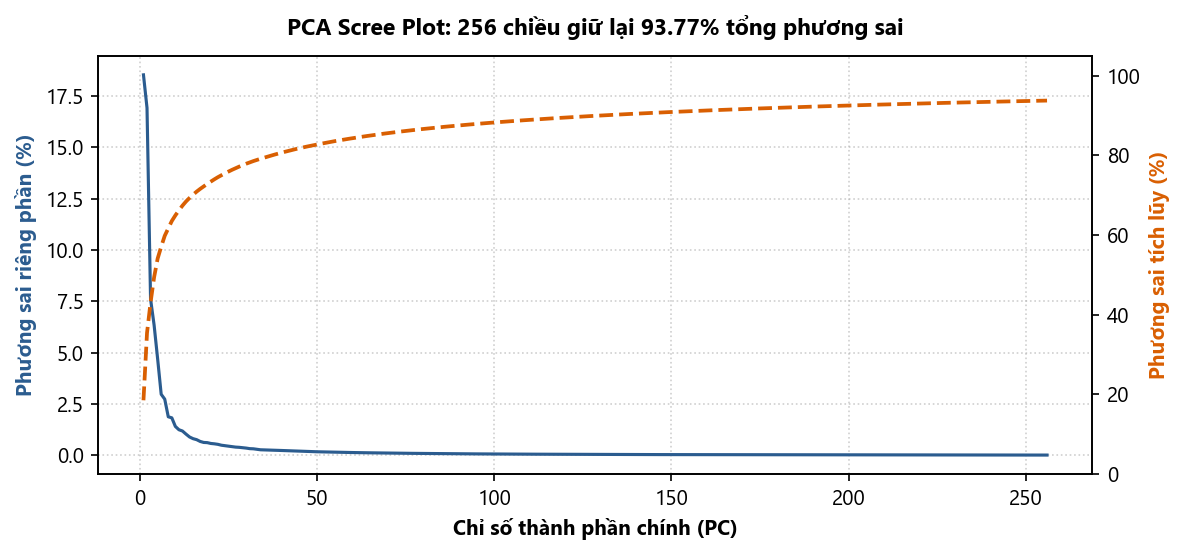

In [5]:
# Nạp cache raw pixel đã trích xuất từ 6.000 ảnh Session 1
cache_s1 = WS / "outputs/feature_ablation/cache/raw_session1.npz"
cache_s2 = WS / "outputs/feature_ablation/cache/raw_session2.npz"

x_s1 = np.load(cache_s1)["X"]
x_s2 = np.load(cache_s2)["X"]

pca = PCA(n_components=256, svd_solver="randomized", random_state=42)
pca.fit(x_s1)

exp_var = pca.explained_variance_ratio_ * 100.0
cum_var = np.cumsum(exp_var)
print(f"✅ PCA 256 chiều giải thích tổng cộng {cum_var[-1]:.2f}% phương sai dữ liệu Session 1.")

# Scree plot phân bố phương sai
fig, ax1 = plt.subplots(figsize=(8, 3.8), dpi=150)
comp_idx = np.arange(1, len(exp_var) + 1)
ax1.plot(comp_idx, exp_var, color="#2b5c8f", lw=1.5, label="Phương sai riêng phần (%)")
ax1.set_xlabel("Chỉ số thành phần chính (PC)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Phương sai riêng phần (%)", color="#2b5c8f", fontsize=10, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = ax1.twinx()
ax2.plot(comp_idx, cum_var, color="#d95f02", lw=1.8, ls="--", label="Phương sai tích lũy (%)")
ax2.set_ylabel("Phương sai tích lũy (%)", color="#d95f02", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 105)

plt.title(f"PCA Scree Plot: 256 chiều giữ lại {cum_var[-1]:.2f}% tổng phương sai", fontsize=11, fontweight="bold", pad=10)
plt.tight_layout()
plt.show()

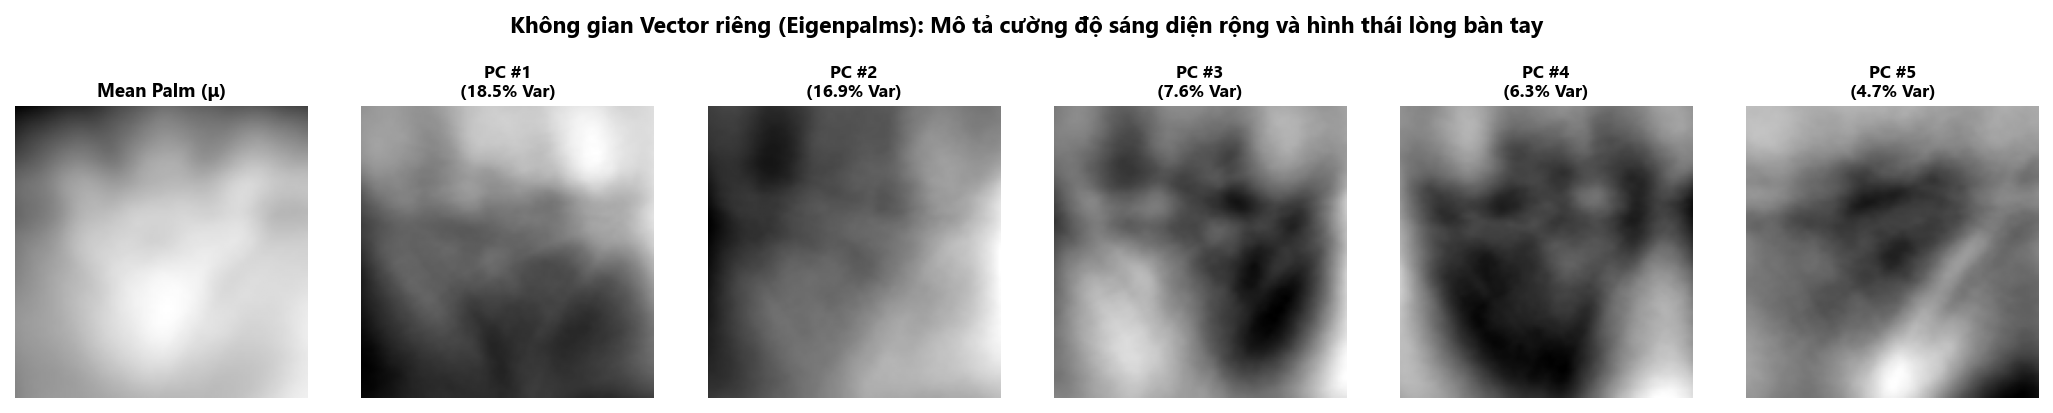

In [6]:
# Trực quan hóa Mean Palm và Top 5 Eigenpalms
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6), dpi=150)

# Mean Palm
axes[0].imshow(pca.mean_.reshape(128, 128), cmap="gray")
axes[0].set_title("Mean Palm (μ)", fontsize=9, fontweight="bold", pad=4)
axes[0].axis("off")

for i in range(5):
    comp = pca.components_[i].reshape(128, 128)
    comp_norm = (comp - comp.min()) / (comp.max() - comp.min() + 1e-12)
    axes[i + 1].imshow(comp_norm, cmap="gray")
    axes[i + 1].set_title(f"PC #{i+1}\n({exp_var[i]:.1f}% Var)", fontsize=8.5, fontweight="bold", pad=4)
    axes[i + 1].axis("off")

fig.suptitle("Không gian Vector riêng (Eigenpalms): Mô tả cường độ sáng diện rộng và hình thái lòng bàn tay", fontsize=11, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

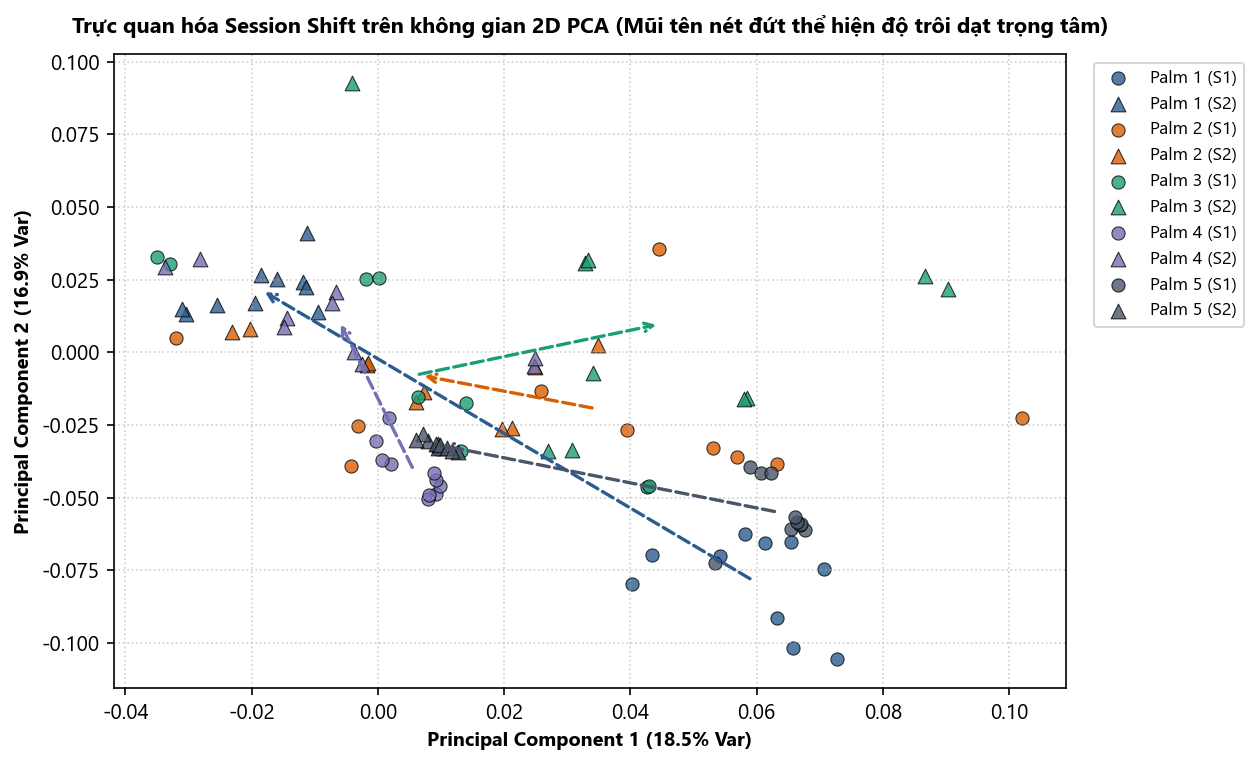

In [7]:
# Trực quan hóa dịch chuyển phiên (Session Shift) trên 2D (PC1 vs PC2) của 5 Palm ID
target_ids = [1, 2, 3, 4, 5]
colors_dark2 = ["#2b5c8f", "#d95f02", "#1b9e77", "#7570b3", "#4a5568"]

z_s1 = pca.transform(x_s1)
z_s2 = pca.transform(x_s2)
df_s1 = df[df.session == "session1"].reset_index(drop=True)
df_s2 = df[df.session == "session2"].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5.2), dpi=150)

for idx, pid in enumerate(target_ids):
    pts1 = z_s1[df_s1.palm_id == pid, :2]
    pts2 = z_s2[df_s2.palm_id == pid, :2]
    
    ax.scatter(pts1[:, 0], pts1[:, 1], color=colors_dark2[idx], marker="o", s=40, alpha=0.8, edgecolors="black", lw=0.5, label=f"Palm {pid} (S1)")
    ax.scatter(pts2[:, 0], pts2[:, 1], color=colors_dark2[idx], marker="^", s=50, alpha=0.8, edgecolors="black", lw=0.5, label=f"Palm {pid} (S2)")
    
    # Mũi tên dịch chuyển trọng tâm
    c1, c2 = pts1.mean(axis=0), pts2.mean(axis=0)
    ax.annotate("", xy=c2, xytext=c1, arrowprops=dict(arrowstyle="->", color=colors_dark2[idx], lw=1.6, ls="--"))

ax.set_xlabel(f"Principal Component 1 ({exp_var[0]:.1f}% Var)", fontsize=9.5, fontweight="bold")
ax.set_ylabel(f"Principal Component 2 ({exp_var[1]:.1f}% Var)", fontsize=9.5, fontweight="bold")
ax.set_title("Trực quan hóa Session Shift trên không gian 2D PCA (Mũi tên nét đứt thể hiện độ trôi dạt trọng tâm)", fontsize=10.5, fontweight="bold", pad=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()